# 03 · Menyaring promosi judi daring di media sosial

**Durasi 50 menit · peserta umum · CPU**

Kita membandingkan model berbasis kata dengan potongan karakter, memilih model dan ambangnya memakai validation, lalu menguji berita/edukasi dan ejaan tersamar. Hasilnya daftar teks untuk ditinjau, bukan keputusan tindak pidana.

| Tahap | Menit |
|---|---:|
| Persiapan | 5 |
| Data dan audit duplikasi | 7 |
| Dua model dan validation | 13 |
| Evaluasi test | 10 |
| Uji tantangan sintetis | 10 |
| Analisis dan penutup | 5 |

**Hubungan dengan slide:** label promosi/nonpromosi, ejaan tersamar, false positive pada berita, serta human-in-the-loop. Praktik ini hanya **teks**; tidak menjalankan OCR, pengenalan gambar, analisis jaringan, atau atribusi pemilik akun.


## 1. Persiapan · 5 menit

Jalankan sel secara berurutan melalui **Runtime → Run all** (Colab) atau **Run → Run All Cells** (Jupyter).
Di komputer: jalankan `pip install -r requirements.txt` sekali sebelum membuka notebook.
Di Colab: buka notebook ini, lalu unggah ZIP folder materi kb_kik saat diminta. Alternatifnya, mount Google Drive dan isi `PROJECT_ROOT` dengan lokasi repo.
Tidak perlu GPU, API key, atau akun layanan AI. Internet hanya diperlukan untuk instalasi awal/unggah ZIP. Versi paket yang dipakai saat pengujian dicantumkan di `requirements.txt`.


In [1]:
import importlib.util, subprocess, sys
# Hanya memasang paket yang belum ada; pada environment yang sudah siap, sel ini offline.
packages = {"numpy":"numpy==2.2.6", "pandas":"pandas==2.2.3",
            "sklearn":"scikit-learn==1.6.1", "matplotlib":"matplotlib==3.10.3"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Paket dasar tersedia. Python", sys.version.split()[0])

Paket dasar tersedia. Python 3.12.14


In [2]:
TOPIC = '03_promosi_judi'
from pathlib import Path
import os,sys,json,zipfile,importlib.util

# Isi lokasi folder repo di sini jika deteksi otomatis gagal.
PROJECT_ROOT = os.environ.get("POLRI_TUTORIAL_ROOT", "")
def is_repo(path):
    return (path / "dataset/01_smsa_final_train.csv").is_file() and (path / "notebook").is_dir()
def find_repo():
    if PROJECT_ROOT:
        return Path(PROJECT_ROOT).expanduser().resolve()
    return next((p for p in [Path.cwd(),*Path.cwd().parents] if is_repo(p)), None)

ROOT = find_repo()
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if ROOT is None and IN_COLAB:
    from google.colab import files
    print("Unggah satu ZIP folder materi kb_kik agar notebook dan dataset tersedia.")
    uploaded = files.upload()
    archives = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Unggah tepat satu ZIP folder materi kb_kik.")
    target = Path(os.environ.get("POLRI_COLAB_UPLOAD_DIR", "/content/polri_tutorial"))
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for item in archive.infolist():
            if not (target / item.filename).resolve().is_relative_to(target.resolve()):
                raise ValueError("Path ZIP tidak aman.")
        archive.extractall(target)
    roots = [p.parent for p in target.rglob("README.md") if is_repo(p.parent)]
    if len(roots) != 1:
        raise ValueError("Struktur ZIP tidak sesuai; isi PROJECT_ROOT secara manual.")
    ROOT = roots[0]
if ROOT is None or not is_repo(ROOT):
    raise FileNotFoundError("Ekstrak repo lengkap atau isi PROJECT_ROOT dengan lokasi repo.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,HTML
from pathlib import Path
import json,re,unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report,confusion_matrix,ConfusionMatrixDisplay,
                             f1_score,precision_score,recall_score)
SEED=42
LABELS=['negative','neutral','positive']
IE_FIELDS=['pelapor','korban','terlapor','saksi','waktu_kejadian','lokasi_kejadian','nominal_disebut','bukti_tersedia']
np.random.seed(SEED)
pd.set_option("display.max_colwidth",115)
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
DATASET = ROOT / "dataset"
OUT = ROOT / "outputs" / TOPIC
OUT.mkdir(parents=True,exist_ok=True)
print("Repo:",ROOT.name,"| Hasil:",OUT.relative_to(ROOT))

Repo: kb_kik | Hasil: outputs\03_promosi_judi


## 2. Apa yang dipelajari model? · 7 menit

Dataset tyogoutomo: label1promosi judi, label0nonpromosi. Definisi dan prosedur anotasi rinci sumber belum tersedia. Jangan menganggap data negatif pasti mencakup semua berita atau edukasi tentang judi.

3.421 baris gabungan split sumber menjadi3.370setelah pembersihan, masking URL/mention, dan deduplikasi input model. Split dibuat ulang agar teks identik sesudah transformasi tidak berada di kedua sisi evaluasi. Kemiripan semantik masih mungkin ada. File raw tidak perlu dibuka atau tautannya dikunjungi.


In [3]:
# Fungsi yang dipakai pada langkah berikut.
def norm(text):
    return ' '.join(unicodedata.normalize('NFKC',str(text)).casefold().split())

def load_splits(root,prefix):
    splits={s:pd.read_csv(Path(root)/'dataset'/f'{prefix}_final_{s}.csv') for s in ['train','val','test']}
    seen=[]
    for s,df in splits.items():
        assert not df['id'].duplicated().any(),f'Duplicate id: {s}'
        column='content_cleaned' if 'content_cleaned' in df else 'content'
        assert df[column].notna().all() and df[column].str.strip().ne('').all()
        current=set(df[column].map(norm));assert len(current)==len(df),f'Duplicate input: {s}'
        for previous in seen:assert not previous & current,'Cross-split text overlap'
        seen.append(current)
    ids=[set(df.id) for df in splits.values()]
    assert all(not ids[i]&ids[j] for i in range(3) for j in range(i+1,3))
    return splits['train'],splits['val'],splits['test']

def summarize_splits(train,val,test):
    return pd.DataFrame([{'split':s,'rows':len(df),**df.label.value_counts().to_dict()}
                         for s,df in [('train',train),('val',val),('test',test)]]).fillna(0)

,split,rows,0,1
0,train,2157,1568,589
1,val,539,392,147
2,test,674,490,184


,content_cleaned,label
2110,BELI ALBERTT UNTUK DI HOLY BUAT APA,0
1373,"kasian doey padahal dia cuma mau ngejaga teman, bahkansaat dia bisa lari pun dia gak mau karna masi mau ngejaga...",0
1040,Tidak ada yang lebih baik selain INDO350,1
1534,"Gak percaya bisa menang sebanyak ini diAERO88, mimpi jadi realita!",1


Jumlah teks sesudah pembersihan: 3370


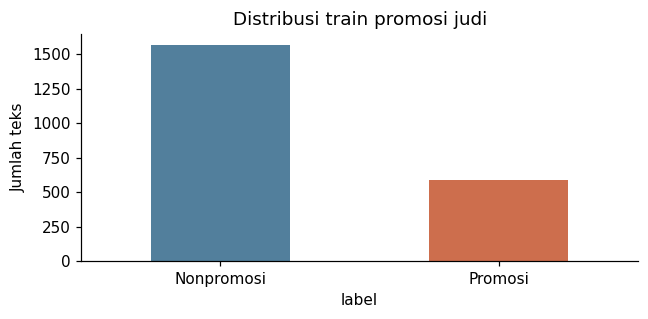

In [4]:
train, val, test = load_splits(ROOT, "03_promosi_judi")
display(summarize_splits(train,val,test))
# Tampilkan versi cleaned sebagai teks biasa, bukan hyperlink promosi.
display(train.groupby("label", group_keys=False).sample(2,random_state=SEED)[["content_cleaned","label"]])
print("Jumlah teks sesudah pembersihan:", len(train) + len(val) + len(test))
fig, ax = plt.subplots(figsize=(6,3))
train.label.value_counts().sort_index().rename(index={0:"Nonpromosi",1:"Promosi"}).plot.bar(ax=ax,color=["#527f9c","#cd6e4d"])
ax.set(title="Distribusi train promosi judi",ylabel="Jumlah teks");ax.tick_params(axis="x",rotation=0)
fig.tight_layout();plt.show();plt.close(fig)

## 3. Kata versus potongan karakter · 13 menit

Model kata belajar kata/frasa. Model karakter belajar potongan3–5 karakter sehingga dapat menangkap sebagian variasi ejaan. Potongan karakter **tidak menjamin** tahan terhadap semua penyamaran atau memahami niat penulis.

Kedua model hanya memakai train. Masing-masing memilih ambang F1 kelas promosi di validation; model terbaik dipilih dari F1 validation yang sama. Test belum digunakan untuk memilih model.


In [5]:
# Fungsi yang dipakai pada langkah berikut.
def threshold_table(y_true,probabilities,thresholds=None):
    if thresholds is None:thresholds=np.round(np.arange(.2,.81,.05),2)
    return pd.DataFrame([{'threshold':float(t),
        'precision':precision_score(y_true,np.asarray(probabilities)>=t,zero_division=0),
        'recall':recall_score(y_true,np.asarray(probabilities)>=t,zero_division=0),
        'f1':f1_score(y_true,np.asarray(probabilities)>=t,zero_division=0)} for t in thresholds])

def select_threshold(validation_table):
    # Tie -> higher threshold, explicit conservative tie policy.
    return float(validation_table.sort_values(['f1','precision','threshold'],ascending=False).iloc[0]['threshold'])

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

specifications = {
    "word": dict(analyzer="word",ngram_range=(1,2),min_df=2,max_features=30000),
    "character": dict(analyzer="char_wb",ngram_range=(3,5),min_df=2,max_features=50000)}
models, validation_rows = {}, []
for name, settings in specifications.items():
    candidate = Pipeline([("tfidf",TfidfVectorizer(**settings)),
        ("classifier",LogisticRegression(C=2.0,class_weight="balanced",max_iter=500,random_state=SEED))])
    candidate.fit(train.content_cleaned,train.label)
    probability = candidate.predict_proba(val.content_cleaned)[:,list(candidate.classes_).index(1)]
    table = threshold_table(val.label,probability)
    threshold = select_threshold(table)
    result = table.loc[table.threshold.eq(threshold)].iloc[0].to_dict()
    validation_rows.append({"model":name,**result});models[name]=candidate
validation_scores = pd.DataFrame(validation_rows).sort_values(["f1","precision"],ascending=False)
display(validation_scores.round(3))
chosen_name = validation_scores.iloc[0]["model"]
THRESHOLD = float(validation_scores.iloc[0].threshold)
model = models[chosen_name]
positive_index = list(model.classes_).index(1)
print("Dikunci sebelum test:",chosen_name,"| ambang",THRESHOLD)

,model,threshold,precision,recall,f1
1,character,0.55,0.993,0.952,0.972
0,word,0.55,0.972,0.952,0.962


Dikunci sebelum test: character | ambang 0.55


## 4. Evaluasi pada test yang dipisahkan · 10 menit

Bandingkan dengan strategi selalu memilih kelas mayoritas. Perhatikan precision promosi: false positive dapat membuat berita pencegahan atau komentar warga ikut tersaring. Recall rendah berarti promosi yang lolos masih banyak.


In [7]:
# Fungsi yang dipakai pada langkah berikut.
def evaluate_classification(y_true,y_pred,labels,title,output_dir):
    output_dir=Path(output_dir);output_dir.mkdir(parents=True,exist_ok=True)
    report=pd.DataFrame(classification_report(y_true,y_pred,labels=labels,output_dict=True,zero_division=0)).T
    fig,ax=plt.subplots(figsize=(6.4,4.8))
    ConfusionMatrixDisplay(confusion_matrix(y_true,y_pred,labels=labels),display_labels=labels).plot(ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set_title(title);fig.tight_layout();fig.savefig(output_dir/'confusion_matrix.png',dpi=150);plt.show();plt.close(fig)
    report.to_csv(output_dir/'classification_report.csv')
    return report

def save_json(path,value):
    Path(path).write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding='utf-8')

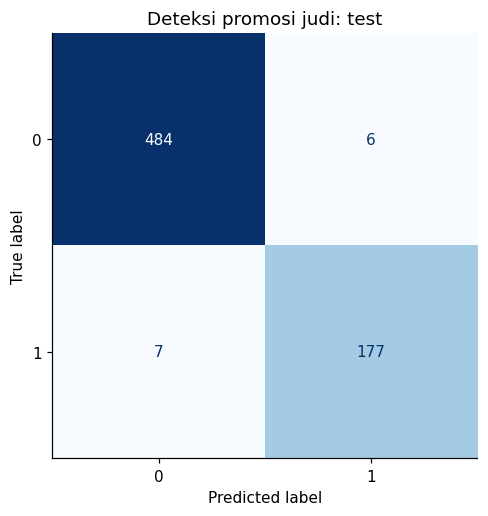

,precision,recall,f1-score,support
0,0.986,0.988,0.987,490.000
1,0.967,0.962,0.965,184.000
accuracy,0.981,0.981,0.981,0.981
macro avg,0.976,0.975,0.976,674.000
weighted avg,0.981,0.981,0.981,674.000


,model,macro_f1
0,Selalu mayoritas,0.420962
1,character,0.975663


False positive:


,id,content_cleaned,label,prediksi,skor_promosi
45,JUDI-train-01290,teman ngemil yang bikin kenyang,0,1,0.564969
174,JUDI-test-00125,1:24:24 tidak ditakdirkan untuk menang🗿🗿,0,1,0.554860
287,JUDI-train-00940,Home Features About Us Deals Merchants News Contact How To Top Up FAQ Terms & Conditions Privacy Notice Informa...,0,1,0.576278
303,JUDI-train-02107,semakin di depan,0,1,0.552558


False negative:


,id,content_cleaned,label,prediksi,skor_promosi
36,JUDI-train-02540,MA.nU.†8.8 jeg menyala wii,1,0,0.251989
53,JUDI-train-01761,Lawati PascolLeher25 atau AcolBurhan88 pasti terubati duka,1,0,0.248975
73,JUDI-test-00241,selamat dätang selamat datang di agen bola judi online terpercaya sukajudi88.com,1,0,0.532417
226,JUDI-train-02074,SELAMAT SORE BANG PASCOLLL INDO35ꉺ SELALU HADIRR!,1,0,0.273362


In [8]:
probability = model.predict_proba(test.content_cleaned)[:,positive_index]
prediction = (probability >= THRESHOLD).astype(int)
report = evaluate_classification(test.label,prediction,[0,1],"Deteksi promosi judi: test",OUT)
display(report.round(3))
baseline = DummyClassifier(strategy="most_frequent").fit(train.content_cleaned,train.label)
display(pd.DataFrame([
    {"model":"Selalu mayoritas","macro_f1":f1_score(test.label,baseline.predict(test.content_cleaned),average="macro")},
    {"model":chosen_name,"macro_f1":f1_score(test.label,prediction,average="macro")}]))
results = test[["id","content_cleaned","label"]].copy()
results["prediksi"]=prediction;results["skor_promosi"]=probability
print("False positive:");display(results.query("label == 0 and prediksi == 1").head(4))
print("False negative:");display(results.query("label == 1 and prediksi == 0").head(4))
results.to_csv(OUT / "test_predictions.csv",index=False)
save_json(OUT / "metrics.json",{"model":chosen_name,"threshold":THRESHOLD,
    "test_macro_f1":float(f1_score(test.label,prediction,average="macro")),
    "promotion_f1":float(f1_score(test.label,prediction))})

## 5. Berita, edukasi, dan ejaan tersamar · 10 menit

Contoh berikut dibuat untuk tutorial. Tidak ada tautan atau situs aktif. `expected_label` merupakan acuan diskusi penulis, belum anotasi manusia independen. Contoh ini terpisah dari test sumber dan tidak dipakai untuk memilih model/ambang.

Pasangan promosi biasa dan tersamar membantu melihat perubahan skor. Menyebut kata “judi” saja tidak cukup menentukan label.


In [9]:
# Fungsi yang dipakai pada langkah berikut.
def clean_text(text):
    """Same transformation used to prepare the classification datasets."""
    text=unicodedata.normalize('NFKC',str(text))
    text=re.sub(r'https?://\S+|www\.\S+','[URL]',text)
    text=re.sub(r'@[\w]+','[AKUN]',text)
    return ' '.join(text.split())

,case_type,content,expected_label,score_word,score_character,prediction
0,news,Polisi menutup situs judi online dan mengimbau warga tidak berjudi.,0,0.554,0.520,0
1,education,Kenali modus promosi slot agar keluarga tidak terjebak perjudian.,0,0.398,0.337,0
2,victim,"Saya kehilangan tabungan karena judi online, sekarang mencari bantuan.",0,0.668,0.501,0
3,criticism,Tolong hapus iklan judi yang muncul di komentar berita ini.,0,0.408,0.238,0
4,ordinary,Diskon sepatu tersedia akhir pekan di toko contoh kami.,0,0.268,0.122,0
5,ordinary,Slot jadwal konsultasi hari Jumat sudah penuh.,0,0.530,0.339,0
6,promotion_plain,"Ayo main slot di [SITUS_FIKTIF], daftar sekarang dan klaim bonus deposit!",1,0.941,0.967,1
7,promotion_masked,"Ay0 m41n sl0t di [SITUS_FIKTIF], d4ft4r skrg dan kl41m b0nus dep0s1t!",1,0.943,0.773,1
8,promotion_plain,"Gabung permainan judi [SITUS_FIKTIF], jackpot menanti dan bonus member baru.",1,0.790,0.925,1
9,promotion_masked,"G a b u n g j u d i [SITUS_FIKTIF], j a c k p o t dan b o n u s member baru.",1,0.754,0.816,1


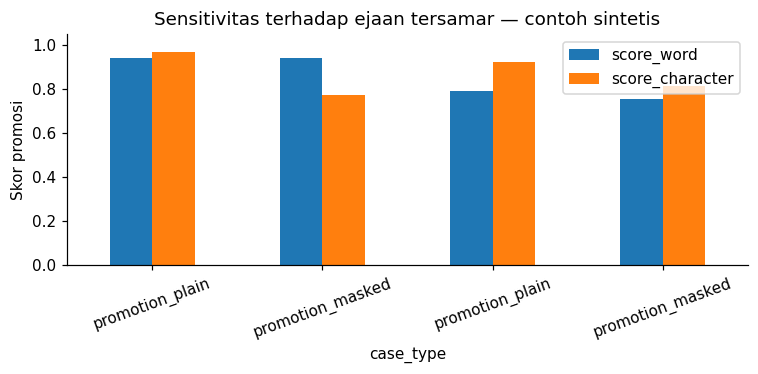

In [10]:
challenge = pd.DataFrame([
    ("news","Polisi menutup situs judi online dan mengimbau warga tidak berjudi.",0),
    ("education","Kenali modus promosi slot agar keluarga tidak terjebak perjudian.",0),
    ("victim","Saya kehilangan tabungan karena judi online, sekarang mencari bantuan.",0),
    ("criticism","Tolong hapus iklan judi yang muncul di komentar berita ini.",0),
    ("ordinary","Diskon sepatu tersedia akhir pekan di toko contoh kami.",0),
    ("ordinary","Slot jadwal konsultasi hari Jumat sudah penuh.",0),
    ("promotion_plain","Ayo main slot di [SITUS_FIKTIF], daftar sekarang dan klaim bonus deposit!",1),
    ("promotion_masked","Ay0 m41n sl0t di [SITUS_FIKTIF], d4ft4r skrg dan kl41m b0nus dep0s1t!",1),
    ("promotion_plain","Gabung permainan judi [SITUS_FIKTIF], jackpot menanti dan bonus member baru.",1),
    ("promotion_masked","G a b u n g j u d i [SITUS_FIKTIF], j a c k p o t dan b o n u s member baru.",1),
    ("counter_speech","Jangan percaya pesan 'daftar slot dan bonus deposit', itu promosi judi.",0),
    ("quoted_news","Berita menjelaskan bagaimana ajakan 'jackpot dan bonus member baru' menjerat korban.",0),
],columns=["case_type","content","expected_label"])
for name,candidate in models.items():
    challenge[f"score_{name}"] = candidate.predict_proba(challenge.content.map(clean_text))[:,list(candidate.classes_).index(1)]
challenge["prediction"] = challenge[f"score_{chosen_name}"].ge(THRESHOLD).astype(int)
display(challenge.round(3))
challenge.to_csv(OUT / "synthetic_challenge.csv",index=False)
fig,ax=plt.subplots(figsize=(7,3.5))
challenge.iloc[6:10].set_index("case_type")[["score_word","score_character"]].plot.bar(ax=ax)
ax.set(title="Sensitivitas terhadap ejaan tersamar — contoh sintetis",ylabel="Skor promosi",ylim=(0,1.05))
ax.tick_params(axis="x",rotation=20);fig.tight_layout();fig.savefig(OUT / "obfuscation_challenge.png",dpi=150);plt.show();plt.close(fig)

## 6. Latihan dan penutup · 5 menit

- Pilih satu berita/edukasi yang salah ditandai. Kata atau frasa apa yang mungkin memicu model?
- Ubah satu huruf pada contoh promosi. Apakah model karakter selalu lebih stabil?
- Jika skor test tinggi tetapi contoh berita sering salah, data tambahan seperti apa yang dibutuhkan?

**Kesimpulan praktik:** data dan definisi label menentukan apa yang dipelajari. F1 test tidak membuktikan ketahanan terhadap semua ejaan tersamar, gambar/video, kampanye terkoordinasi, atau perubahan promosi baru. Sinyal teks belum mengidentifikasi pemilik akun dan bukan bukti tindak pidana. Setiap tindakan memerlukan verifikasi manusia.

Sumber: [dataset tyogoutomo](https://github.com/tyogoutomo/INDONESIAN_ONLINE_GAMBLING_WEBSITE_PROMOTION_DATASET), [text feature extraction scikit-learn](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction). Lisensi dan perubahan data ada di `dataset/README.md`.
